# Intermediate EncoderMap: Different Topologies

**Welcome**

Welcome to the intermediate part of the EncoderMap tutorials. The notebooks in this section contain more in-depth explanations of the concepts in EncoderMap.

## What are different topologies

With the word *'topology'* we mean the connectivity of a protein. Think of it as a graph. The nodes are the atoms and the connections are the bonds. Two topologies are identical if their graphs are identical. Two proteins are different if you exchange or remove a single atom. 

For some proteins, we observe and describe so-called *protein families*. In such families, proteins with similar (but not identical) sequences perform very similar tasks in an organism. As their sequences are different proteins in such families exhibit different topologies. Using standard features (distances, angles, dihedrals) that depend on the sequence can't be used classically to describe and characterize such protein families. A pre-selection of features has to be performed on these topologically different proteins to achieve feature spaces with the same number of dimensions for all topologies.

**EncoderMap III introduces a way to forego the pre-selection by allowing the input to the `AngleDihedralCartesianEncoderMap` to be sparse.**

Authors: Kevin Sawade (kevin.sawade@uni-konstanz.de), Tobias Lemke, Christine Peter (christine.peter@uni-konstanz.de)

Find the documentation of EncoderMap:

https://ag-peter.github.io/encodermap

**Goals**

In this tutorial, you will learn:

- How to 

In [6]:
# !pip install "git+https://github.com/AG-Peter/encodermap.git@main"
# !pip install -r pip install -r https://raw.githubusercontent.com/AG-Peter/encodermap/main/tests/test_requirements.md

## Imports

In [33]:
import encodermap as em
import numpy as np
import networkx as nx
import plotly.graph_objects as go
import plotly.express as px
import warnings

%load_ext autoreload
%autoreload 2
%config Completer.use_jedi = False

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Fix tensorflow seed for reproducibility

In [8]:
import tensorflow as tf
tf.random.set_seed(1)

## Load the trajectories

We use EncoderMap's `TrajEnsemble` class to load the trajectories and do the feature alignment.

In [20]:
traj_files = ["glu7.xtc", "asp7.xtc"]
top_files = ["glu7.pdb", "asp7.pdb"]

trajs = em.load(traj_files, top_files, common_str=["glu7", "asp7"])

There's an issue with the proteins in these trajectories. They are missing a connection between the C-terminal hydroxy oxygen and hydrogen. The `GLU7-HO` atom is extra.

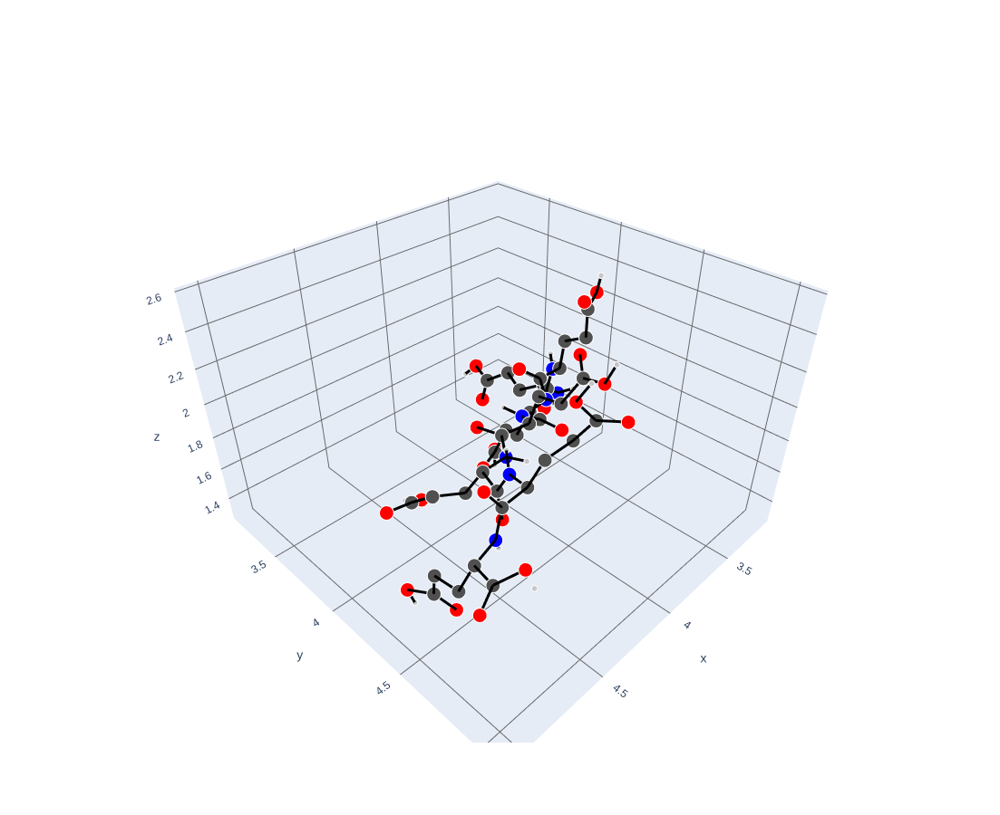

In [21]:
em.plot.plot_ball_and_stick(trajs[0], highlight="bonds")

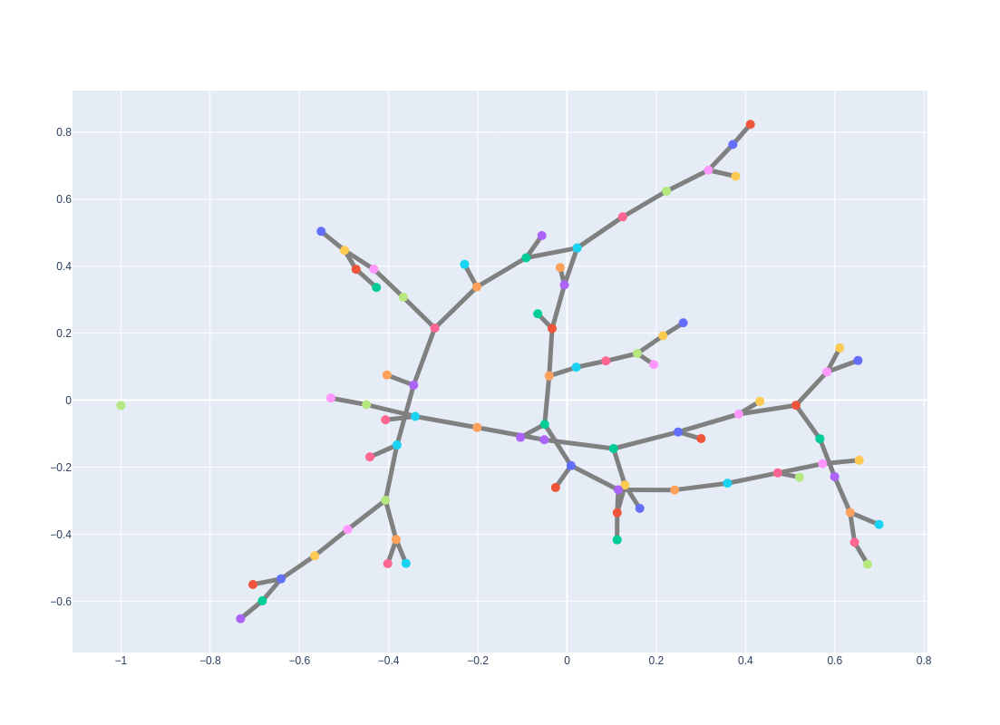

In [22]:
G = trajs[0].top.to_bondgraph()

# Generate positions for the nodes
pos = nx.spring_layout(G)

# Create a Plotly figure
fig = go.Figure()

# Add edges to the figure
for u, v, data in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    fig.add_trace(go.Scatter(x=[x0, x1], y=[y0, y1], mode='lines', line=dict(width=5, color='gray')))

# Add nodes to the figure
for node in G.nodes():
    x, y = pos[node]
    fig.add_trace(go.Scatter(x=[x], y=[y], mode='markers', marker=dict(size=10), hovertemplate="%{customdata}", customdata=[str(node)]))

# Show the figure
fig.update_layout({"width": 800, "height": 800, "showlegend": False})
fig.show()

This can be fixed with EncoderMap, by defining custom amino acids:

In [23]:
custom_aas = {
    "ASP": (
        "A",
        {
            "optional_bonds": [
                ("N", "H1"),
                ("N", "H2"),
                ("N", "H"),
                ("N", "CA"),
                ("CA", "CB"),
                ("CB", "CG"),
                ("CG", "OD1"),
                ("CG", "OD2"),
                ("OD2", "HD2"),
                ("CA", "C"),
                ("C", "O"),
                ("C", "OT"),
                ("O", "HO"),
                ("C", "+N"),
            ],
        },
    ),
    "GLU": (
        "E",
        {
            "optional_bonds": [
                ("N", "H1"),
                ("N", "H2"),
                ("N", "H"),
                ("N", "CA"),
                ("CA", "CB"),
                ("CB", "CG"),
                ("CG", "CD"),
                ("CD", "OE1"),
                ("CD", "OE2"),
                ("OE2", "HE2"),
                ("CA", "C"),
                ("C", "O"),
                ("C", "OT"),
                ("O", "HO"),
                ("C", "+N"),
            ],
        },
    ),
}


trajs.load_custom_topology(custom_aas)

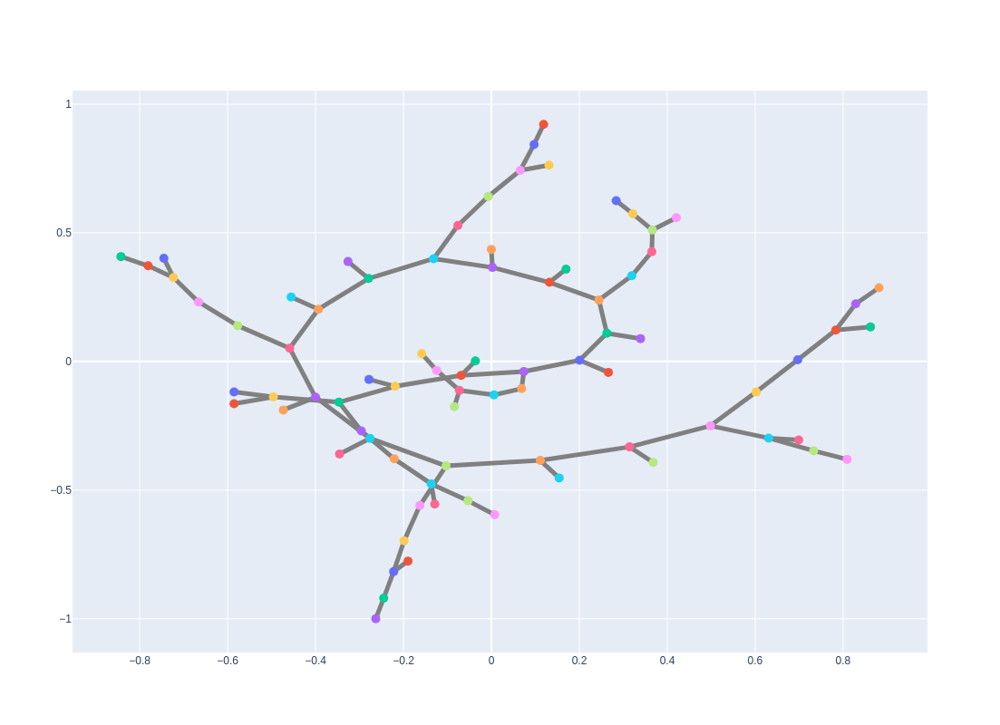

In [24]:
G = trajs[0].top.to_bondgraph()

# Generate positions for the nodes
pos = nx.spring_layout(G)

# Create a Plotly figure
fig = go.Figure()

# Add edges to the figure
for u, v, data in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    fig.add_trace(go.Scatter(x=[x0, x1], y=[y0, y1], mode='lines', line=dict(width=5, color='gray')))

# Add nodes to the figure
for node in G.nodes():
    x, y = pos[node]
    fig.add_trace(go.Scatter(x=[x], y=[y], mode='markers', marker=dict(size=10), hovertemplate="%{customdata}", customdata=[str(node)]))

# Show the figure
fig.update_layout({"width": 800, "height": 800, "showlegend": False})
fig.show()

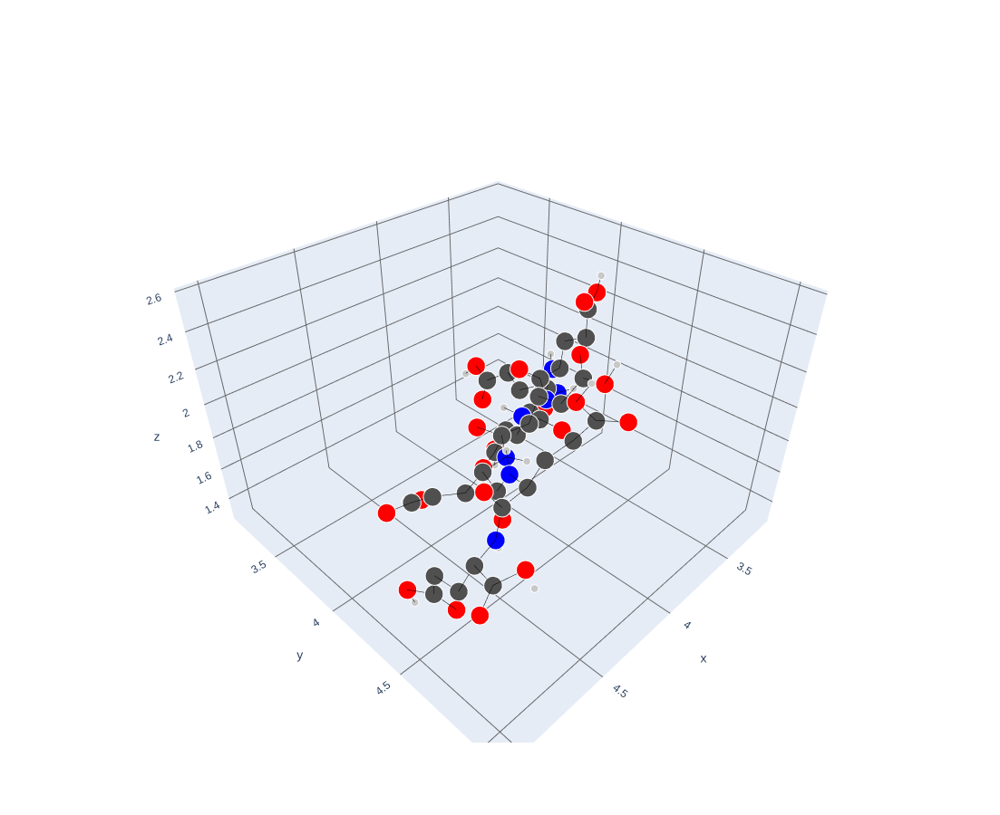

In [25]:
em.plot.plot_ball_and_stick(trajs[0], highlight="atoms")

Load the CVs with the `ensemble=True` options. This option will tell EncoderMap to assume the trajectories to be part of the same ensemble. To highlight the key differences let use first look at a copy of the ASP7 trajectory and run a full featurization on that.

In [47]:
asp7_copy = trajs.trajs_by_common_str["asp7"][0].copy()
asp7_copy.load_CV("all")

/home/kevin/git/encoder_map_private/encodermap/trajinfo/trajinfo_utils.py:1299: UserWarning:

Your custom topology for residue name=ASP resSeq=None index=None does not define atoms for the dihedral PSI. If this dihedral consists of standard atom names, it will be considered for dihedral calculations. If this dihedral should not be present in your custom topology you need to explicitly delete it by adding 'PSI_ATOMS': 'delete' to your custom_topology. If you want this dihedral to be present in your topology, you can ignore this warning.

/home/kevin/git/encoder_map_private/encodermap/trajinfo/trajinfo_utils.py:1299: UserWarning:

Your custom topology for residue name=GLU resSeq=None index=None does not define atoms for the dihedral PSI. If this dihedral consists of standard atom names, it will be considered for dihedral calculations. If this dihedral should not be present in your custom topology you need to explicitly delete it by adding 'PSI_ATOMS': 'delete' to your custom_topology. If

Getting output of 5 features for asp7:   0%|          | 0/5 [00:00<?, ?it/s]

Notice how the labels of the sidechain diherdal features contain the name of the residue (`ASP`).

In [31]:
asp7_copy._CVs

<xarray.Dataset>
Dimensions:                             (traj_num: 1, frame_num: 10001,
                                         ATOM: 21, COORDS: 3,
                                         CENTRAL_DISTANCES: 20,
                                         CENTRAL_ANGLES: 19,
                                         CENTRAL_DIHEDRALS: 18,
                                         SIDE_DIHEDRALS: 14, ATOM_NO: 4)
Coordinates:
  * traj_num                            (traj_num) int64 1
    traj_name                           (traj_num) <U4 'asp7'
  * frame_num                           (frame_num) int64 0 1 2 ... 9999 10000
  * ATOM                                (ATOM) <U33 'ATOM     N:    0 ASP:   ...
  * COORDS                              (COORDS) <U10 'POSITION X' ... 'POSIT...
    time                                (frame_num) float32 0.0 500.0 ... 5e+06
  * CENTRAL_DISTANCES                   (CENTRAL_DISTANCES) <U81 'CENTERDISTA...
  * CENTRAL_ANGLES                      (CENTRAL_ANGLES) <U113 'CENTERANGLE  ...
  * CENTRAL_DIHEDRALS                   (CENTRAL_DIHEDRALS) <U39 'CENTERDIH P...
  * SIDE_DIHEDRALS                      (SIDE_DIHEDRALS) <U39 'SIDECHDIH CHI1...
  * ATOM_NO                             (ATOM_NO) int64 0 1 2 3
Data variables:
    central_cartesians                  (traj_num, frame_num, ATOM, COORDS) float32 ...
    central_distances                   (traj_num, frame_num, CENTRAL_DISTANCES) float32 ...
    central_angles                      (traj_num, frame_num, CENTRAL_ANGLES) float32 ...
    central_dihedrals                   (traj_num, frame_num, CENTRAL_DIHEDRALS) float32 ...
    side_dihedrals                      (traj_num, frame_num, SIDE_DIHEDRALS) float32 ...
    central_cartesians_feature_indices  (traj_num, ATOM) int32 0 1 2 ... 49 50
    central_distances_feature_indices   (traj_num, CENTRAL_DISTANCES, ATOM_NO) float64 ...
    central_angles_feature_indices      (traj_num, CENTRAL_ANGLES, ATOM_NO) float64 ...
    central_dihedrals_feature_indices   (traj_num, CENTRAL_DIHEDRALS, ATOM_NO) int32 ...
    side_dihedrals_feature_indices      (traj_num, SIDE_DIHEDRALS, ATOM_NO) int32 ...
Attributes:
    length_units:   nm
    time_units:     ps
    feature_axes:   ['SIDE_DIHEDRALS', 'ATOM', 'CENTRAL_DISTANCES', 'CENTRAL_...
    full_path:      asp7.xtc
    topology_file:  asp7.pdb

Now if we run a full featurization with `ensemble=True`.

<span style="color:lightgray;">Hint: Here we're using the <tt>with warnings.catch_warnings()</tt> to catch the same warnings informing us about the backbone angles.</span>

In [48]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    trajs.load_CVs("all", ensemble=True)

Output()

Notice, how the features are now labelled with more generic labels. These generic labels allow EncoderMap to combine feature spaces from different topologies.

In [49]:
trajs._CVs

<xarray.Dataset>
Dimensions:                             (frame_num: 10001, ATOM: 21, COORDS: 3,
                                         CENTRAL_DISTANCES: 20,
                                         CENTRAL_ANGLES: 19,
                                         CENTRAL_DIHEDRALS: 18,
                                         SIDE_DIHEDRALS: 21, ATOM_NO: 4,
                                         traj_num: 2)
Coordinates:
  * frame_num                           (frame_num) int64 0 1 2 ... 9999 10000
  * ATOM                                (ATOM) <U2 '1' '2' '3' ... '20' '21'
  * COORDS                              (COORDS) <U10 'POSITION X' ... 'POSIT...
  * CENTRAL_DISTANCES                   (CENTRAL_DISTANCES) <U18 'CENTERDISTA...
  * CENTRAL_ANGLES                      (CENTRAL_ANGLES) <U18 'CENTERANGLE   ...
  * CENTRAL_DIHEDRALS                   (CENTRAL_DIHEDRALS) <U18 'CENTERDIH P...
  * SIDE_DIHEDRALS                      (SIDE_DIHEDRALS) <U18 'SIDECHDIH CHI1...
  * ATOM_NO                             (ATOM_NO) int64 0 1 2 3
  * traj_num                            (traj_num) int64 0 1
    traj_name                           (traj_num) <U4 'glu7' 'asp7'
    time                                (traj_num, frame_num) float32 0.0 ......
Data variables:
    central_cartesians                  (traj_num, frame_num, ATOM, COORDS) float32 ...
    central_distances                   (traj_num, frame_num, CENTRAL_DISTANCES) float32 ...
    central_angles                      (traj_num, frame_num, CENTRAL_ANGLES) float32 ...
    central_dihedrals                   (traj_num, frame_num, CENTRAL_DIHEDRALS) float32 ...
    side_dihedrals                      (traj_num, frame_num, SIDE_DIHEDRALS) float32 ...
    central_cartesians_feature_indices  (traj_num, ATOM) int32 0 3 10 ... 49 50
    central_distances_feature_indices   (traj_num, CENTRAL_DISTANCES, ATOM_NO) float64 ...
    central_angles_feature_indices      (traj_num, CENTRAL_ANGLES, ATOM_NO) float64 ...
    central_dihedrals_feature_indices   (traj_num, CENTRAL_DIHEDRALS, ATOM_NO) int32 ...
    side_dihedrals_feature_indices      (traj_num, SIDE_DIHEDRALS, ATOM_NO) float64 ...
Attributes:
    length_units:    nm
    time_units:      ps
    feature_axes:    ['SIDE_DIHEDRALS', 'ATOM', 'CENTRAL_DISTANCES', 'CENTRAL...
    angle_units:     rad
    full_paths:      ['asp7.xtc', 'glu7.xtc']
    topology_files:  ['asp7.pdb', 'glu7.pdb']

Let us take a look at the `SIDECHDIH CHI3   1` label, specifically. Notice, how for `glu7` the angle is defined, whereas `asp7` exhibits `np.nan` at these positions.

In [53]:
trajs._CVs["side_dihedrals"].sel({"SIDE_DIHEDRALS": "SIDECHDIH CHI3   1", "traj_num": 0})

<xarray.DataArray 'side_dihedrals' (frame_num: 10001)>
array([-0.23724079,  1.5991355 , -2.6023357 , ...,  1.7465132 ,
       -1.3356311 , -1.5160242 ], dtype=float32)
Coordinates:
  * frame_num       (frame_num) int64 0 1 2 3 4 5 ... 9996 9997 9998 9999 10000
    SIDE_DIHEDRALS  <U18 'SIDECHDIH CHI3   1'
    traj_num        int64 0
    traj_name       <U4 'glu7'
    time            (frame_num) float32 0.0 500.0 1e+03 ... 5e+06 5e+06
Attributes:
    length_units:    nm
    time_units:      ps
    full_paths:      ['asp7.xtc', 'glu7.xtc']
    topology_files:  ['asp7.pdb', 'glu7.pdb']
    angle_units:     rad
    feature_axis:    SIDE_DIHEDRALS

In [54]:
trajs._CVs["side_dihedrals"].sel({"SIDE_DIHEDRALS": "SIDECHDIH CHI3   1", "traj_num": 1})

<xarray.DataArray 'side_dihedrals' (frame_num: 10001)>
array([nan, nan, nan, ..., nan, nan, nan], dtype=float32)
Coordinates:
  * frame_num       (frame_num) int64 0 1 2 3 4 5 ... 9996 9997 9998 9999 10000
    SIDE_DIHEDRALS  <U18 'SIDECHDIH CHI3   1'
    traj_num        int64 1
    traj_name       <U4 'asp7'
    time            (frame_num) float32 0.0 500.0 1e+03 ... 5e+06 5e+06
Attributes:
    length_units:    nm
    time_units:      ps
    full_paths:      ['asp7.xtc', 'glu7.xtc']
    topology_files:  ['asp7.pdb', 'glu7.pdb']
    angle_units:     rad
    feature_axis:    SIDE_DIHEDRALS

## Create the AngleDihedralCartesianEncoderMap

The AngleDihedralCartesianEncoderMap tries to learn all of the geometric features of a protein. The angles (backbone angles, backbone dihedrals, sidechain dihedrals) are passed through a neuronal network autoencoder, while the distances between the backbone atoms are used to create cartesian coordinates from the learned angles. The generated cartesians and the input (true) cartesians are used to construct pairwise C$_\alpha$ distances, which are then also weighted using sketchmap's sigmoid function. The `cartesian_cost_scale_soft_start` gradually increases the contribution of this cost function to the overall model loss.

In [55]:
p = em.ADCParameters(use_backbone_angles=True,
                     distance_cost_scale=1,
                     auto_cost_scale=0.1,
                     cartesian_cost_scale_soft_start=(50, 80),
                     n_neurons = [500, 250, 125, 2],
                     activation_functions = ['', 'tanh', 'tanh', 'tanh', ''],
                     use_sidechains=True,
                     summary_step=1,
                     tensorboard=True,
                     periodicity=2*np.pi,
                     n_steps=100,
                     checkpoint_step=1000,
                     dist_sig_parameters = (4.5, 12, 6, 1, 2, 6),
                     main_path=em.misc.run_path('runs/asp7_glu7_asp8'),
                     model_api='functional',
                    )
emap = em.AngleDihedralCartesianEncoderMap(trajs, p)

Output files are saved to runs/asp7_glu7_asp8/run2 as defined in 'main_path' in the parameters.
input shapes are:
{'central_cartesians': (20002, 21, 3), 'central_distances': (20002, 20), 'side_dihedrals': TensorShape([20002, 21]), 'central_dihedrals': (20002, 18), 'central_angles': (20002, 19)}
Saved a text-summary of the model and an image in runs/asp7_glu7_asp8/run2, as specified in 'main_path' in the parameters.


train

In [56]:
history = emap.train()

Calculating references: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████| 78/78 [00:00<00:00, 235.50it/s]


After 77 steps setting cost references: {'dihedral_cost': 1.7226728, 'angle_cost': 0.29572558, 'cartesian_cost': 0.19267249} to parameters.


100%|███████████████████████████████████████████████████████████████████████| 100/100 [00:15<00:00,  6.62it/s, Loss after step 100=3.02, Cartesian cost scale=1]


Saving the model to runs/asp7_glu7_asp8/run2/saved_model_2025-06-19T20:37:01+02:00.keras. Use `em.AngleDihedralCartesianEncoderMap.from_checkpoint('runs/asp7_glu7_asp8/run2')` to load the most recent model, or `em.AngleDihedralCartesianEncoderMap.from_checkpoint('runs/asp7_glu7_asp8/run2/saved_model_2025-06-19T20:37:01+02:00.keras')` to load the model with specific weights..
This model has a subclassed encoder, which can be loaded independently. Use `tf.keras.load_model('runs/asp7_glu7_asp8/run2/saved_model_2025-06-19T20:37:01+02:00_encoder.keras')` to load only this model.
This model has a subclassed decoder, which can be loaded independently. Use `tf.keras.load_model('runs/asp7_glu7_asp8/run2/saved_model_2025-06-19T20:37:01+02:00_decoder.keras')` to load only this model.


## Plot the result

In the result (longer training would be beneficial here), the projection area of asp7 and glu7 are separated.

Due to the size of the provided data 190019, I need to chunk it, which takes longer. Sit back, grab a coffee...
Due to the size of the provided data 190019, I need to chunk it, which takes longer. Sit back, grab a coffee...
Due to the size of the provided data 190019, I need to chunk it, which takes longer. Sit back, grab a coffee...
Due to the size of the provided data 190019, I need to chunk it, which takes longer. Sit back, grab a coffee...


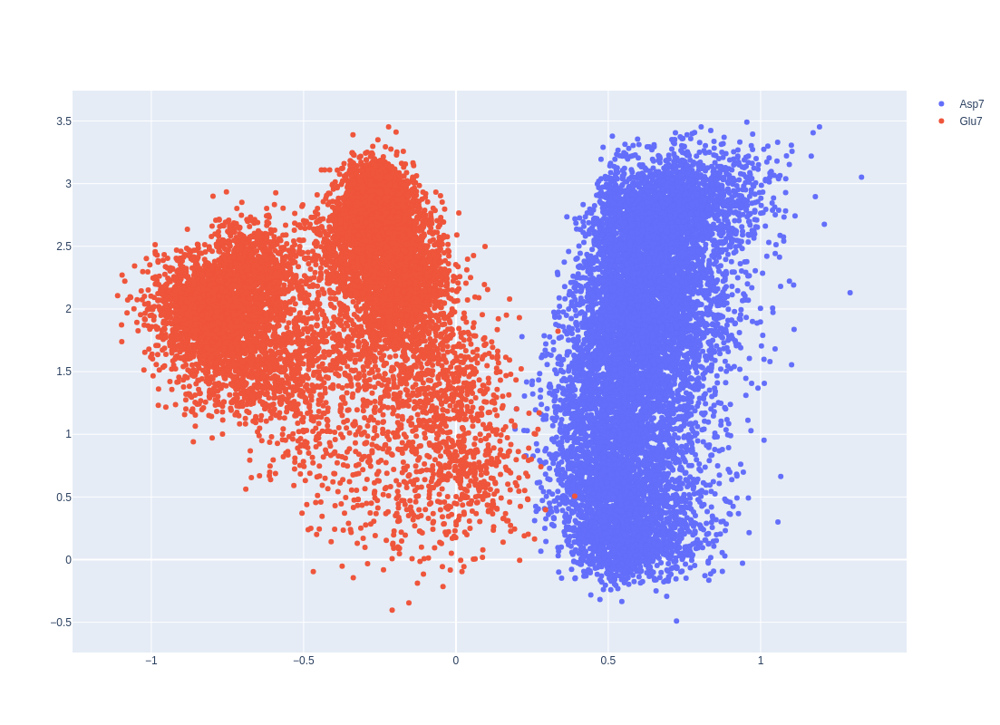

In [57]:
ids = (trajs.name_arr == "asp7").astype(int)
glu7_lowd = emap.encode()[ids == 0]
asp7_lowd = emap.encode()[ids == 1]

fig = go.Figure(
    data=[
        go.Scatter(x=asp7_lowd[:, 0], y=asp7_lowd[:, 1], name="Asp7", mode="markers"),
        go.Scatter(x=glu7_lowd[:, 0], y=glu7_lowd[:, 1], name="Glu7", mode="markers"),
    ],
)
fig.update_layout({"height": 800, "width": 800})
fig.show()

## Create a new trajectory

Using the `InteractivePlotting` class, we can easily generate new molecular conformations by using the decoder part of the neural network. If you're running an interactive notebook, you can use the notebook or qt5 backend and play around with the InteractivePlotting.

In [96]:
sess = em.InteractivePlotting(emap, ball_and_stick=False)

GridspecLayout(children=(HTML(value='<h2>EncoderMap Dashboard for kevin in runs/asp7_glu7_asp8/run2</h2>', lay…

For static notebooks, we load the points along the path and generate new molecular conformations from them.

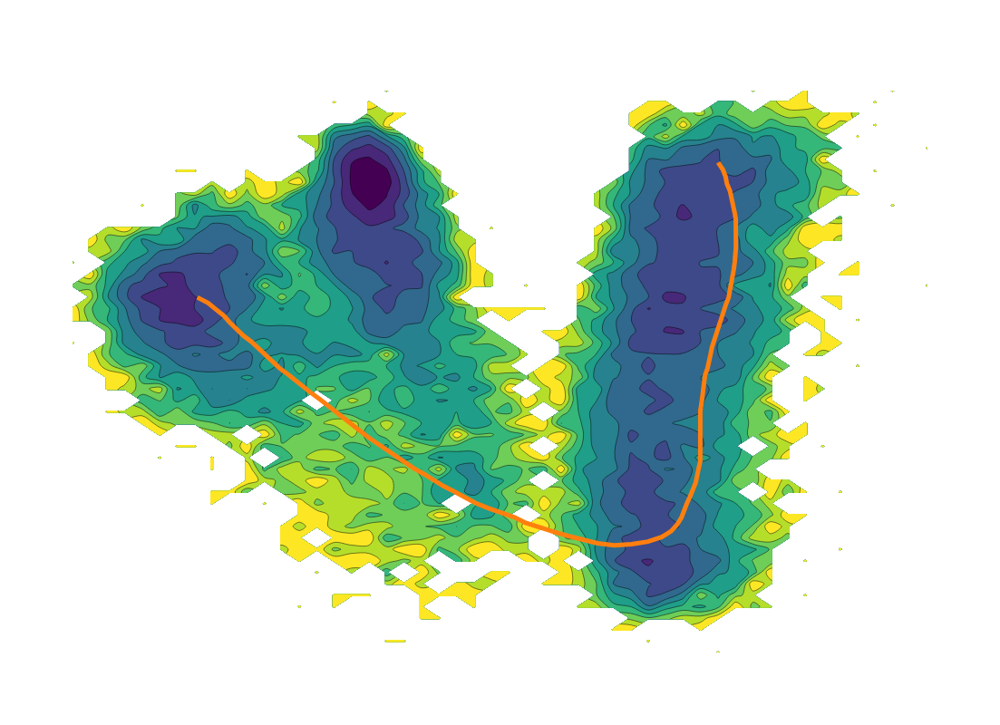

In [71]:
from encodermap.plot.plotting import _plot_free_energy

path = np.load("path.npy")

fig = go.Figure(
    data=[
        _plot_free_energy(*trajs.lowd.T, bins=50),
        go.Scatter(
            x=path[:, 0],
            y=path[:, 1],
            mode="lines",
            name="",
            line_width=5,
            customdata=[i for i in range(len(path))],
            hovertemplate="%{customdata}",
            showlegend=False,
        ),
    ]
)
layout = {
    "width": 800,
    "height": 800,
    "template": "none",
    "xaxis": {
        "showgrid": False,
        "showline": False,
        "zeroline": False,
        "showticklabels": False,
        "ticks": "",
    },
    "yaxis": {
        "showgrid": False,
        "showline": False,
        "zeroline": False,
        "showticklabels": False,
        "ticks": "",
    },
    "plot_bgcolor": "rgba(0, 0, 0, 0)",
    "paper_bgcolor": 'rgba(0, 0, 0, 0)',
}
fig.update_layout(**layout)
fig.show()

And generate molecular conformations from the path. For the `emap.generate()` method, we can choose which topology to use.

In [82]:
generated_asp7 = emap.generate(path, top="asp7", backend="mdtraj")
generated_glu7 = emap.generate(path, top="glu7", backend="mdtraj")

Backmapping...:   0%|          | 0/3200 [00:00<?, ?it/s]

/home/kevin/git/encoder_map_private/encodermap/trajinfo/trajinfo_utils.py:1299: UserWarning:

Your custom topology for residue name=ASP resSeq=None index=None does not define atoms for the dihedral PSI. If this dihedral consists of standard atom names, it will be considered for dihedral calculations. If this dihedral should not be present in your custom topology you need to explicitly delete it by adding 'PSI_ATOMS': 'delete' to your custom_topology. If you want this dihedral to be present in your topology, you can ignore this warning.

/home/kevin/git/encoder_map_private/encodermap/trajinfo/trajinfo_utils.py:1299: UserWarning:

Your custom topology for residue name=GLU resSeq=None index=None does not define atoms for the dihedral PSI. If this dihedral consists of standard atom names, it will be considered for dihedral calculations. If this dihedral should not be present in your custom topology you need to explicitly delete it by adding 'PSI_ATOMS': 'delete' to your custom_topology. If

Backmapping...:   0%|          | 0/3900 [00:00<?, ?it/s]

In [83]:
generated_asp7

<mdtraj.Trajectory with 100 frames, 57 atoms, 7 residues, and unitcells at 0x732dcc4784f0>

In [84]:
generated_glu7

<mdtraj.Trajectory with 100 frames, 80 atoms, 7 residues, and unitcells at 0x732dcc4a1a80>

In [85]:
import nglview as nv

In [97]:
view = nv.show_mdtraj(generated_glu7)
view.clear_representations()
view.add_representation("hyperball")
view

NGLWidget(max_frame=99)